# My tree vs scikit-learn 🌳

I wanted to see how my first model compares to the real scikit-learn decision tree. I am using the same train/test data for both. The timings will be different on every computer.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from time import perf_counter
from sklearn.datasets import load_iris
from sklearn.model_selection import train_test_split
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay
from sklearn.tree import DecisionTreeClassifier
from model import decisiontree

seed = 42
max_depth = 4

## A small comparison function

This runs each model once. Speed results are rough measurements, not a serious benchmark.

In [2]:
def compare_models(name, X_train, X_test, y_train, y_test):
    scores = []
    for label, model in [("My tree", decisiontree(max_depth=max_depth)), ("sklearn", DecisionTreeClassifier(max_depth=max_depth, random_state=seed))]:
        start = perf_counter()
        model.fit(X_train, y_train)
        fit_time = (perf_counter() - start) * 1000
        start = perf_counter()
        pred = model.predict(X_test)
        predict_time = (perf_counter() - start) * 1000
        scores.append({"Dataset":name, "Model":label, "Accuracy":accuracy_score(y_test, pred), "Precision":precision_score(y_test, pred, average="macro", zero_division=0), "Recall":recall_score(y_test, pred, average="macro", zero_division=0), "F1":f1_score(y_test, pred, average="macro", zero_division=0), "Fit ms":fit_time, "Predict ms":predict_time})
    return pd.DataFrame(scores)

## Iris

Iris is already available with scikit-learn.

In [3]:
iris = load_iris(as_frame=True)
Xi_train, Xi_test, yi_train, yi_test = train_test_split(iris.data, iris.target, test_size=.25, random_state=seed, stratify=iris.target)
iris_results = compare_models("Iris", Xi_train, Xi_test, yi_train, yi_test)
display(iris_results.round(4))

,Dataset,Model,Accuracy,Precision,Recall,F1,Fit ms,Predict ms
0,Iris,My tree,0.9211,0.9246,0.9231,0.923,14.0291,0.4654
1,Iris,sklearn,0.9211,0.9246,0.9231,0.923,1.3119,0.4267


### Iris accuracy and F1

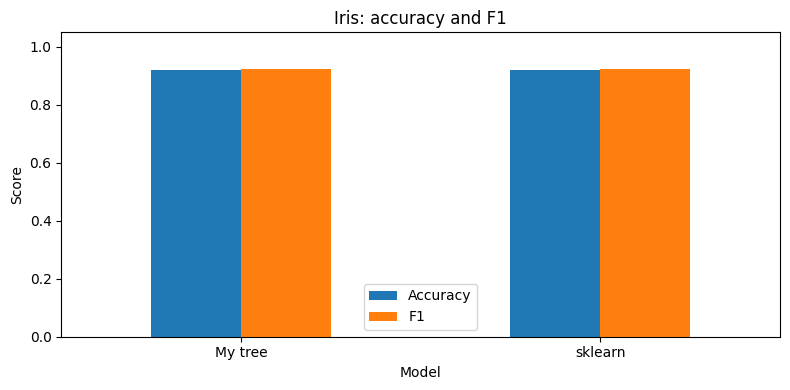

In [4]:
ax = iris_results.set_index("Model")[["Accuracy", "F1"]].plot.bar(rot=0, figsize=(8, 4))
ax.set_ylim(0, 1.05)
ax.set_ylabel("Score")
ax.set_title("Iris: accuracy and F1")
plt.tight_layout()
plt.show()

### Iris training and prediction speed

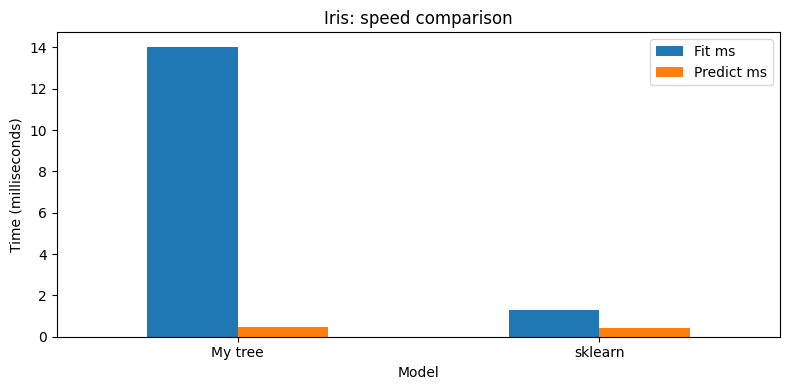

In [5]:
fig, ax = plt.subplots(figsize=(8, 4))
iris_results.set_index("Model")[["Fit ms", "Predict ms"]].plot.bar(ax=ax, rot=0)
ax.set_ylabel("Time (milliseconds)")
ax.set_title("Iris: speed comparison")
plt.tight_layout()
plt.show()

### Iris confusion matrices

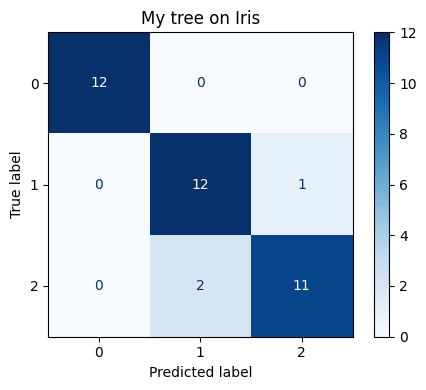

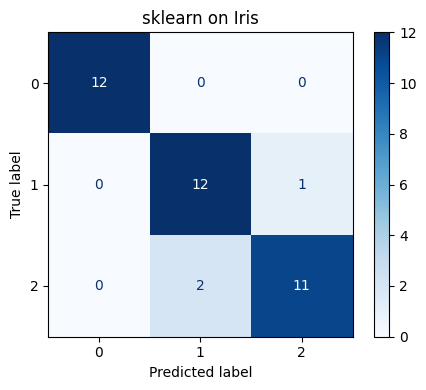

In [6]:
for name, model in [("My tree", decisiontree(max_depth=max_depth)), ("sklearn", DecisionTreeClassifier(max_depth=max_depth, random_state=seed))]:
    model.fit(Xi_train, yi_train)
    preds = model.predict(Xi_test)
    fig, ax = plt.subplots(figsize=(5, 4))
    ConfusionMatrixDisplay.from_predictions(yi_test, preds, ax=ax, cmap="Blues")
    ax.set_title(name + " on Iris")
    plt.tight_layout()
    plt.show()

## Titanic

Use the public Titanic CSV or save it as `titanic.csv` beside this notebook. Without the CSV and without internet access, this part will be skipped rather than using made-up data.

Dataset: https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv

In [7]:
from pathlib import Path

titanic_path = "titanic.csv" if Path("titanic.csv").exists() else "https://raw.githubusercontent.com/datasciencedojo/datasets/master/titanic.csv"
try:
    titanic = pd.read_csv(titanic_path)
    print("Titanic rows:", len(titanic))
except Exception as e:
    titanic = None
    print("Could not load Titanic. Download titanic.csv to this folder and run these cells again.")

Could not load Titanic. Download titanic.csv to this folder and run these cells again.


### Preparing Titanic

I use passenger class, sex, age, family counts, fare, and port. Missing numeric values are filled with the **training-set median**, and categories are converted to numeric columns using only training data so both models see identical inputs.

In [8]:
titanic_results = None
if titanic is not None:
    features = ["Pclass", "Sex", "Age", "SibSp", "Parch", "Fare", "Embarked"]
    X = titanic[features].copy()
    y = titanic["Survived"]
    Xt_train, Xt_test, yt_train, yt_test = train_test_split(X, y, test_size=.25, random_state=seed, stratify=y)
    Xt_train, Xt_test = Xt_train.copy(), Xt_test.copy()
    for col in ["Pclass", "Age", "SibSp", "Parch", "Fare"]:
        median = Xt_train[col].median()
        Xt_train[col] = Xt_train[col].fillna(median)
        Xt_test[col] = Xt_test[col].fillna(median)
    for col in ["Sex", "Embarked"]:
        Xt_train[col] = Xt_train[col].fillna("Unknown")
        Xt_test[col] = Xt_test[col].fillna("Unknown")
    Xt_train = pd.get_dummies(Xt_train, columns=["Sex", "Embarked"], dtype=int)
    Xt_test = pd.get_dummies(Xt_test, columns=["Sex", "Embarked"], dtype=int)
    Xt_test = Xt_test.reindex(columns=Xt_train.columns, fill_value=0)
    titanic_results = compare_models("Titanic", Xt_train, Xt_test, yt_train, yt_test)
    display(titanic_results.round(4))

### Titanic accuracy and F1

In [9]:
if titanic_results is not None:
    ax = titanic_results.set_index("Model")[["Accuracy", "F1"]].plot.bar(rot=0, figsize=(8, 4))
    ax.set_ylim(0, 1.05)
    ax.set_title("Titanic: accuracy and F1")
    ax.set_ylabel("Score")
    plt.tight_layout()
    plt.show()

### Titanic speed

In [10]:
if titanic_results is not None:
    ax = titanic_results.set_index("Model")[["Fit ms", "Predict ms"]].plot.bar(rot=0, figsize=(8, 4))
    ax.set_title("Titanic: speed comparison")
    ax.set_ylabel("Time (milliseconds)")
    plt.tight_layout()
    plt.show()

### Titanic confusion matrices

In [11]:
if titanic_results is not None:
    for name, model in [("My tree", decisiontree(max_depth=max_depth)), ("sklearn", DecisionTreeClassifier(max_depth=max_depth, random_state=seed))]:
        model.fit(Xt_train, yt_train)
        preds = model.predict(Xt_test)
        fig, ax = plt.subplots(figsize=(5, 4))
        ConfusionMatrixDisplay.from_predictions(yt_test, preds, ax=ax, cmap="Blues")
        ax.set_title(name + " on Titanic")
        plt.tight_layout()
        plt.show()

## Overall results

In [12]:
all_results = pd.concat([iris_results] + ([titanic_results] if titanic_results is not None else []), ignore_index=True)
display(all_results.round(4))

,Dataset,Model,Accuracy,Precision,Recall,F1,Fit ms,Predict ms
0,Iris,My tree,0.9211,0.9246,0.9231,0.923,14.0291,0.4654
1,Iris,sklearn,0.9211,0.9246,0.9231,0.923,1.3119,0.4267


### Comparing accuracy across datasets

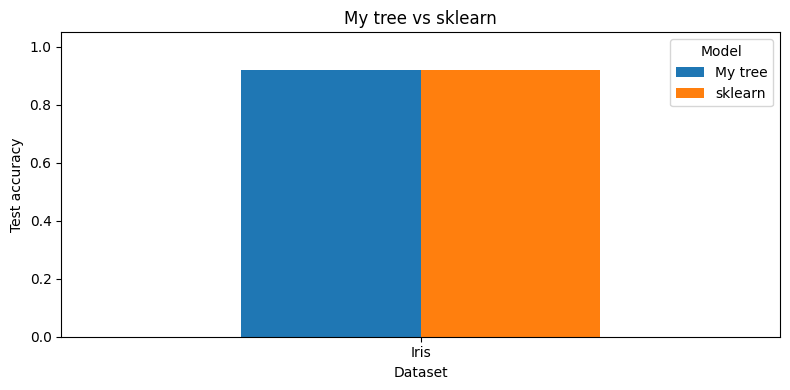

In [13]:
fig, ax = plt.subplots(figsize=(8, 4))
all_results.pivot(index="Dataset", columns="Model", values="Accuracy").plot.bar(ax=ax, rot=0)
ax.set_ylim(0, 1.05)
ax.set_ylabel("Test accuracy")
ax.set_title("My tree vs sklearn")
plt.tight_layout()
plt.show()

## What I noticed

The two trees do not always pick identical splits, and my Python implementation usually takes longer to train. That is fine for this project: I mainly built it to understand the algorithm.

The timings are single runs, so they are not reliable performance benchmarks.